# 2-fish recording: accuracy of four pipelines, all EODs vs the better list of good frames

Same plots as `EOD_accuracy_plots_3fish.ipynb`. % of EODs assigned to fish 1 (the only emitter):
- **numerical, sink at tail tip** and **numerical, sink 5% from tail tip**: my numerical field model, BEM conductivities (interior 100 × water, skin 0.05 × water over
  0.005 cm), sign fixed (warm colours), from `results/eod_ground_truth/conductivities/eod_assignments.csv`;
- **analytic, SLEAP midline** (spline through the SLEAP keypoints) and **analytic, mask midline** (my mask midline): Denis'
  analytic model, his latest run (cold colours); the mask-midline run is read from
  `results/eod_assignment_2_fish_silent/eod_assignment_summary.csv` (A → fish 1, B → fish 0).

Two sets of EODs: all 18,770, and the 3,501 in `results/eod_ground_truth/good_frames_better_list.csv` (common good frames, every
fish's mask ≥ 0.8 × its median length; made in `EOD_QC_length_limit_2fish.ipynb`). EODs without a pick (no mask or midline) count as
wrong. Distance = smallest mask-edge distance from fish 1 to fish 0 (`gap_cm`; 158 EODs without a distance are left out of the
distance plot only). Error bars: 95% Wilson intervals (left out of the good-frames distance panel, where they overlap).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

OUT = 'results/eod_ground_truth/conductivities'
EMITTER = 1
DENIS_MASK = "fish | Denis' pipeline with my mask midline"
PIPES = {   # label: (column, colour, marker)
    'numerical, sink at tail tip': ('fish | BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip', '#C8361E', 'o'),
    'numerical, sink 5% from tail tip': ('fish | BEM σ (interior 100, skin 0.05, 0.005 cm), sink 5% from tail tip', '#F08A24', 'o'),
    'analytic, SLEAP midline': ("fish | Denis' pipeline (latest run)", '#1F5FBF', 'D'),
    'analytic, mask midline': (DENIS_MASK, '#17A0B0', 'D'),
}
A = pd.read_csv(f'{OUT}/eod_assignments.csv', index_col='row')
S = pd.read_csv('results/eod_assignment_2_fish_silent/eod_assignment_summary.csv')
assert (S.Frame.to_numpy() == A.Frame.to_numpy()).all()
assert (S.discharging_fish.map({'A': 1, 'B': 0}).to_numpy() == A["fish | Denis' pipeline (latest run)"].to_numpy()).all()
A[DENIS_MASK] = S.discharging_fish_mask_midline.map({'A': 1, 'B': 0}).to_numpy()          # NaN: no mask midline
better = A.Frame.isin(pd.read_csv('results/eod_ground_truth/good_frames_better_list.csv').frame).to_numpy()
SETS = {'all EODs': np.ones(len(A), bool), 'better list of good frames': better}
assert better.sum() == 3501

def wilson(k, n, z=1.96):
    '''95% Wilson interval of k successes in n trials, in %.'''
    p = k / n; c = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n); hw = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * (c - hw), 100 * (c + hw)

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'grid.linewidth': 0.8, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b', 'xtick.color': '#5a5a55',
                     'ytick.color': '#5a5a55'})

## % correct against the distance to the other fish

10 bins with equal numbers of EODs per panel; points at the bin median distance.

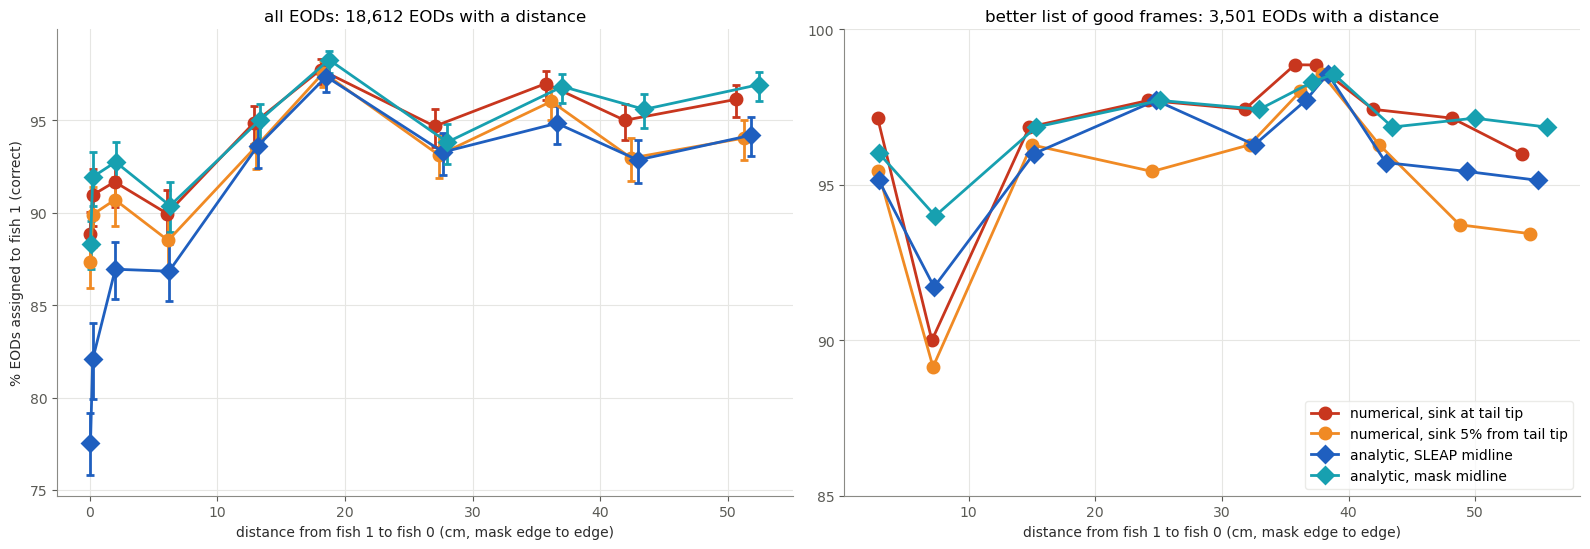

all EODs


,"numerical, sink at tail tip","numerical, sink 5% from tail tip","analytic, SLEAP midline","analytic, mask midline"
median distance (cm),,,,
0.1,88.9,87.3,77.5,88.3
0.2,91.0,89.9,82.1,91.9
2.0,91.7,90.7,86.9,92.7
6.2,90.0,88.5,86.8,90.4
13.1,94.8,93.6,93.6,95.0
18.4,97.7,97.6,97.4,98.3
27.5,94.7,93.1,93.3,93.8
36.4,97.0,96.0,94.8,96.8
42.7,95.0,93.0,92.9,95.6


better list of good frames


,"numerical, sink at tail tip","numerical, sink 5% from tail tip","analytic, SLEAP midline","analytic, mask midline"
median distance (cm),,,,
2.9,97.2,95.4,95.2,96.0
7.2,90.0,89.1,91.7,94.0
15.1,96.9,96.3,96.0,96.9
24.6,97.7,95.4,97.7,97.7
32.4,97.4,96.3,96.3,97.4
36.4,98.9,98.0,97.7,98.3
38.1,98.9,98.6,98.6,98.6
42.7,97.4,96.3,95.7,96.9
49.1,97.1,93.7,95.4,97.1


In [2]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.6))
tables = {}
for a, (s, m) in zip(axs, SETS.items()):
    sub = A[m & A.gap_cm.notna().to_numpy()]
    gr = sub.groupby(pd.qcut(sub.gap_cm, 10, duplicates='drop'), observed=True); x = gr.gap_cm.median().to_numpy(); t = {}
    for j, (nm, (col, c, mk)) in enumerate(PIPES.items()):
        k = gr[col].apply(lambda v: (v == EMITTER).sum()).to_numpy(); n = gr.size().to_numpy(); pct = 100 * k / n; lo, hi = wilson(k, n)
        err = None if s == 'better list of good frames' else [pct - lo, hi - pct]   # no error bars on the good-frames panel
        a.errorbar(x * (1 + 0.012 * (j - 1.5)), pct, yerr=err, color=c, marker=mk, ms=8, ls='-', lw=2, capsize=3, mfc=c, mew=2, label=nm)
        t[nm] = pct
    tables[s] = pd.DataFrame(t, index=pd.Index(x.round(1), name='median distance (cm)')).round(1)
    a.set(title=f'{s}: {len(sub):,} EODs with a distance', xlabel='distance from fish 1 to fish 0 (cm, mask edge to edge)')
axs[0].set_ylabel('% EODs assigned to fish 1 (correct)'); axs[1].set(ylim=(85, 100), yticks=np.arange(85, 101, 5))
axs[1].legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#e6e6e3', fontsize=10)
plt.tight_layout(); fig.savefig(f'{OUT}/figures/accuracy_vs_distance_4pipelines.png', dpi=130); plt.show()
for s, t in tables.items(): print(s); display(t)

## Overall % correct

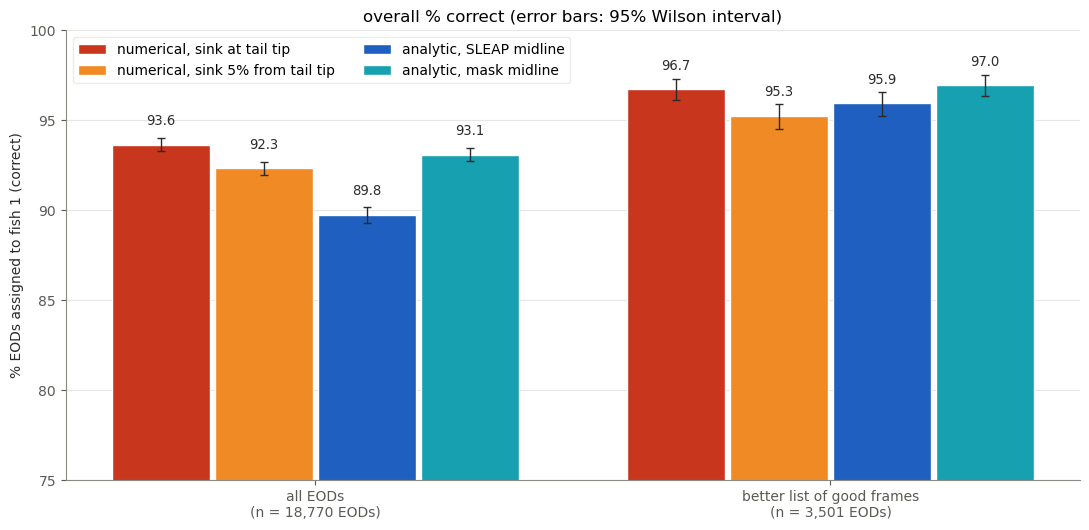

% correct  \
EODs                       pipeline                                      
all EODs                   numerical, sink at tail tip           93.65   
                           numerical, sink 5% from tail tip      92.33   
                           analytic, SLEAP midline               89.75   
                           analytic, mask midline                93.09   
better list of good frames numerical, sink at tail tip           96.74   
                           numerical, sink 5% from tail tip      95.26   
                           analytic, SLEAP midline               95.94   
                           analytic, mask midline                96.97   

                                                             95% CI low  \
EODs                       pipeline                                       
all EODs                   numerical, sink at tail tip            93.29   
                           numerical, sink 5% from tail tip       91.94   
                           analytic, SLEAP midline                89.31   
                           analytic, mask midline                 92.72   
better list of good frames numerical, sink at tail tip            96.10   
                           numerical, sink 5% from tail tip       94.50   
                           analytic, SLEAP midline                95.24   
                           analytic, mask midline                 96.35   

                                                             95% CI high  \
EODs                       pipeline                                        
all EODs                   numerical, sink at tail tip             93.99   
                           numerical, sink 5% from tail tip        92.71   
                           analytic, SLEAP midline                 90.18   
                           analytic, mask midline                  93.44   
better list of good frames numerical, sink at tail tip             97.28   
                           numerical, sink 5% from tail tip        95.91   
                           analytic, SLEAP midline                 96.55   
                           analytic, mask midline                  97.49   

                                                              n EODs  
EODs                       pipeline                                   
all EODs                   numerical, sink at tail tip       18770.0  
                           numerical, sink 5% from tail tip  18770.0  
                           analytic, SLEAP midline           18770.0  
                           analytic, mask midline            18770.0  
better list of good frames numerical, sink at tail tip        3501.0  
                           numerical, sink 5% from tail tip   3501.0  
                           analytic, SLEAP midline            3501.0  
                           analytic, mask midline             3501.0

In [3]:
rows = {}
for s, m in SETS.items():
    for nm, (col, *_ ) in PIPES.items():
        k, n = int((A.loc[m, col] == EMITTER).sum()), int(m.sum()); lo, hi = wilson(k, n)
        rows[(s, nm)] = {'% correct': 100 * k / n, '95% CI low': lo, '95% CI high': hi, 'n EODs': n}
overall = pd.DataFrame(rows).T; overall.index.names = ['EODs', 'pipeline']
overall.to_csv(f'{OUT}/accuracy_overall_4pipelines.csv')

fig, ax = plt.subplots(figsize=(11, 5.4))
w = 0.19
for j, (nm, (col, c, mk)) in enumerate(PIPES.items()):
    v = np.array([overall.loc[(s, nm), '% correct'] for s in SETS])
    lo = v - np.array([overall.loc[(s, nm), '95% CI low'] for s in SETS]); hi = np.array([overall.loc[(s, nm), '95% CI high'] for s in SETS]) - v
    xs = np.arange(len(SETS)) + (j - 1.5) * (w + 0.01)
    ax.bar(xs, v, w, color=c, edgecolor='white', lw=1, label=nm)
    ax.errorbar(xs, v, yerr=[lo, hi], fmt='none', ecolor='#2b2b2b', capsize=3, lw=1)
    for xx, vv in zip(xs, v): ax.text(xx, vv + 0.9, f'{vv:.1f}', ha='center', va='bottom', fontsize=9.5, color='#2b2b2b')
ax.set_xticks(np.arange(len(SETS))); ax.set_xticklabels([f'{s}\n(n = {int(m.sum()):,} EODs)' for s, m in SETS.items()])
ax.set(ylim=(75, 100), ylabel='% EODs assigned to fish 1 (correct)', title='overall % correct (error bars: 95% Wilson interval)')
ax.set_axisbelow(True); ax.grid(axis='x', visible=False)
ax.legend(loc='upper left', ncol=2, frameon=True, facecolor='white', edgecolor='#e6e6e3', fontsize=10)
plt.tight_layout(); fig.savefig(f'{OUT}/figures/accuracy_overall_4pipelines.png', dpi=130); plt.show()
display(overall.round(2))